In [109]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from pointpats import centrography
import contextily as ctx
from matplotlib_scalebar.scalebar import ScaleBar

In [79]:
df = pd.read_excel("base_puntos.xlsx")

In [80]:
barrios = gpd.read_file("barrio/Barrio.shp")
barrios = barrios.to_crs(epsg=3116)
barrios.head()


,OBJECTID,CODIGO,NOMBRE,ABREVIATUR,IDENTIFICA,LIMITECOMU,ZHFISICAGE,LIMITEMUNI,VIGENCIA_F,SUBTIPO_BA,LINK_DOCUM,SHAPE_AREA,SHAPE_LEN,geometry
0,682,0415,Miranda,None,0415,04,None,001,NaT,1,None,230378.299048,2359.939726,"POLYGON ((835882.969 1186244.166, 835880.291 1..."
1,683,Inst_14,U.D. Atanasio Girardot,None,Inst_14,11,None,001,NaT,1,None,417796.539390,3340.183294,"POLYGON ((833040.147 1184063.675, 833036.748 1..."
2,684,1421,Patio Bonito,None,1421,14,None,001,NaT,1,None,729056.068030,4102.132884,"POLYGON ((834187.352 1179035.347, 834180.369 1..."
3,685,0308,Manrique Oriental,None,0308,03,None,001,NaT,1,None,373291.559375,3004.096249,"POLYGON ((837295.391 1185007.935, 837301.144 1..."
4,686,0110,La Esperanza No.2,None,0110,01,None,001,NaT,1,None,67338.260559,1299.674139,"POLYGON ((838001.067 1187831.715, 838002.246 1..."


In [81]:
barrios = barrios[~barrios["LIMITECOMU"].isin(["50", "60", "70", "80", "90", "SN01", "SN02"])]

In [82]:
barrios.columns

Index(['OBJECTID', 'CODIGO', 'NOMBRE', 'ABREVIATUR', 'IDENTIFICA',
       'LIMITECOMU', 'ZHFISICAGE', 'LIMITEMUNI', 'VIGENCIA_F', 'SUBTIPO_BA',
       'LINK_DOCUM', 'SHAPE_AREA', 'SHAPE_LEN', 'geometry'],
      dtype='str')

In [83]:
df.columns

Index(['caso', 'anio', 'fecha_hecho', 'dia_nombre', 'mes_calendario', 'hora',
       'minuto', 'jornada', 'nombre_bien_sijin', 'bien', 'categoria_bien',
       'grupo_bien', 'conducta_especial', 'conducta', 'modalidad', 'sexo',
       'edad', 'rango_edad', 'rango_edad_pisc', 'cod_barrio', 'barrio',
       'cod_comuna', 'comuna', 'plana_x', 'plana_y', 'geo_x', 'geo_y',
       'cuadrante', 'lugar', 'grupo_lugar', 'valor', 'modelo', 'asegurado',
       'linea_marca', 'estado_civil', 'medio_transporte',
       'medio_transporte_agresor', 'sede_receptora', 'grupo_sede_receptora',
       'marca', 'color', 'arma_medio', 'fecha_actualizacion', 'pais_nace'],
      dtype='str')

In [84]:
# Convertir df en gdf

gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df['plana_x'], df['plana_y']),
    crs='EPSG:3116'
)

In [85]:
gdf.head()

,caso,anio,fecha_hecho,dia_nombre,mes_calendario,hora,minuto,jornada,nombre_bien_sijin,bien,...,medio_transporte,medio_transporte_agresor,sede_receptora,grupo_sede_receptora,marca,color,arma_medio,fecha_actualizacion,pais_nace,geometry
0,1,2018,2018-01-01,Lunes,Enero,21,0,Noche,ADEREZO,Salsa,...,Caminata,Caminata,Poblado,Estación,Sin dato,Oro,Palanca,2020-07-27,COLOMBIA,POINT (835653.175 1177083.583)
1,1,2018,2018-01-01,Lunes,Enero,0,0,Madrugada,PESO COLOMBIANO EFECTIVO,Peso,...,Caminata,Caminata,Villa Hermosa,Estación,Sin dato,Sin dato,No,2020-07-27,COLOMBIA,POINT (838070.826 1182781.54)
2,1,2018,2018-01-02,Martes,Enero,6,0,Mañana,TELEVISOR,Electrodoméstico video y audio y accesorios,...,Motocicleta,Caminata,Villa Hermosa,Estación,LG,Sin dato,No,2020-07-27,COLOMBIA,POINT (837198.031 1183083.518)
3,1,2018,2018-01-02,Martes,Enero,0,0,Madrugada,CARPA,Carpa,...,Caminata,Caminata,Villa Hermosa,Estación,Sin dato,Blanco,Objeto contundente,2020-07-27,COLOMBIA,POINT (837585.731 1182104.068)
4,1,2018,2018-01-03,Miércoles,Enero,0,0,Madrugada,ADEREZO,Salsa,...,Caminata,Caminata,Laureles,Estación,Sin dato,Oro,Palanca,2020-07-27,COLOMBIA,POINT (832215.49 1181926.564)


In [86]:
# Trabajemos con 2018:

gdf_2018 = gdf[gdf['anio'] == 2018].copy()

#extraemos la matriz de coordenadas que pointpats necesita para trabajar.
coords = np.column_stack([gdf_2018.geometry.x, gdf_2018.geometry.y])

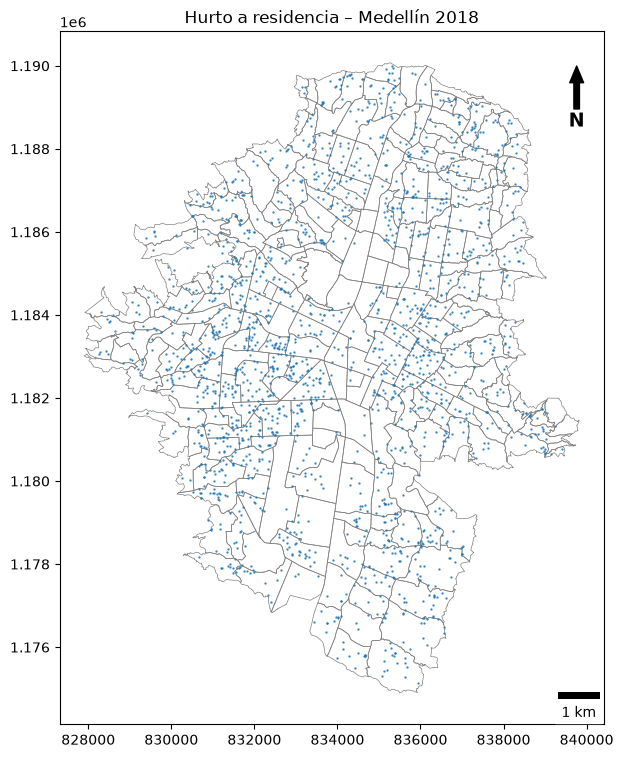

In [129]:
fig, ax = plt.subplots(figsize=(9, 9))
barrios.plot(ax=ax, facecolor="none", edgecolor="gray", linewidth=0.5)
ax.scatter(coords[:, 0], coords[:, 1], s=0.5, alpha=0.8)
ax.set_aspect('equal')
ax.set_title('Hurto a residencia – Medellín 2018')
ax.add_artist(ScaleBar(1, 'm', length_fraction=0.1, location='lower right'))
ax.annotate('N', xy=(0.95, 0.95), xytext=(0.95, 0.87),
            arrowprops=dict(facecolor='black', width=4, headwidth=10),
            ha='center', va='center', fontsize=14, fontweight='bold',
            xycoords='axes fraction')
plt.show()

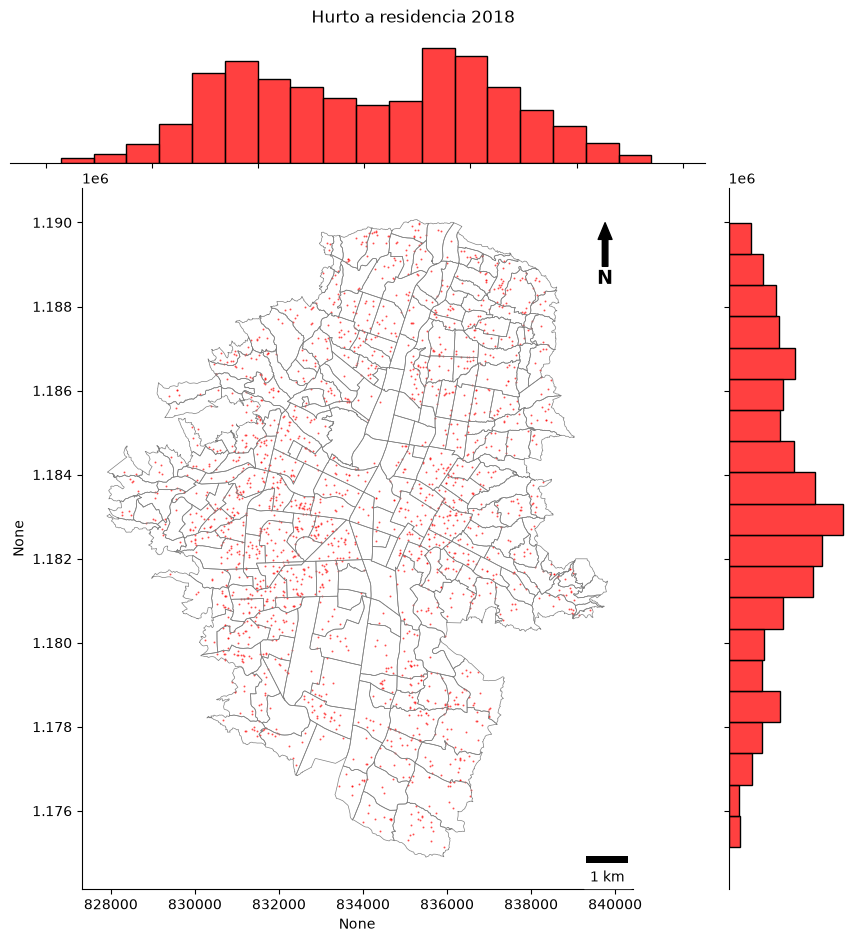

In [130]:
from matplotlib_scalebar.scalebar import ScaleBar

g = sns.jointplot(x=coords[:, 0], y=coords[:, 1], s=2, alpha=0.7, color='red', height=9)
barrios.plot(ax=g.ax_joint, facecolor='none', edgecolor='gray', linewidth=0.5)
g.ax_joint.set_aspect('equal')

# Barra de escala
scalebar = ScaleBar(1, 'm', length_fraction=0.1, location='lower right')
g.ax_joint.add_artist(scalebar)

# Flecha de norte
x, y, arrow_length = 0.95, 0.95, 0.08
g.ax_joint.annotate('N', xy=(x, y), xytext=(x, y - arrow_length),
                     arrowprops=dict(facecolor='black', width=4, headwidth=10),
                     ha='center', va='center', fontsize=14, fontweight='bold',
                     xycoords='axes fraction')

g.fig.suptitle('Hurto a residencia 2018', y=1.02)
plt.show()

In [88]:
# Ahora vamos con la primera técnica de centrografía: el centro medio y el centro mediano:

mean_center = centrography.mean_center(coords)
med_center = centrography.euclidean_median(coords)

print('Centro medio:', mean_center)
print('Centro mediano:', med_center)

Centro medio: [ 834025.40161329 1183195.54814273]
Centro mediano: [ 833746.4858973  1183135.24836364]


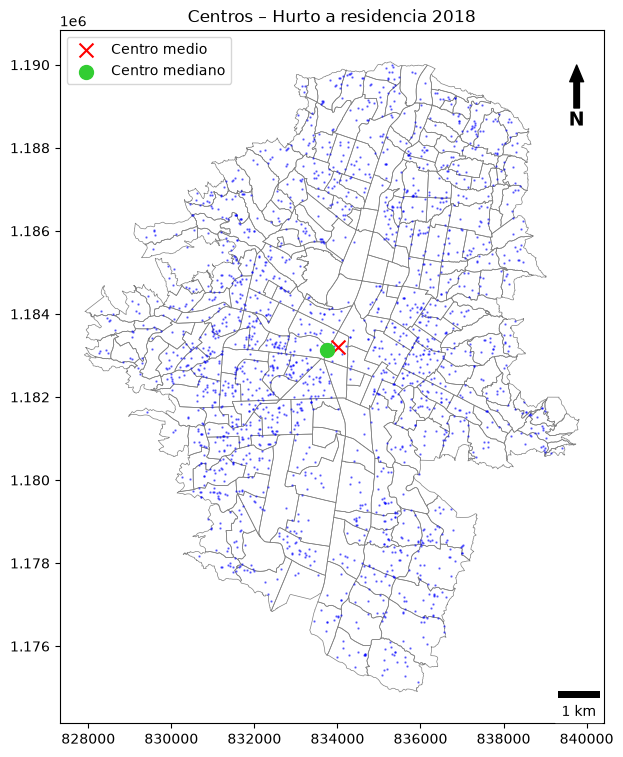

In [131]:
fig, ax = plt.subplots(figsize=(9, 9))
barrios.plot(ax=ax, facecolor="none", edgecolor="gray", linewidth=0.5)
ax.scatter(coords[:, 0], coords[:, 1], s=0.5, alpha=0.5, color='blue')
ax.scatter(*mean_center, color='red', marker='x', s=100, label='Centro medio')
ax.scatter(*med_center, color='limegreen', marker='o', s=100, label='Centro mediano')
ax.set_aspect('equal')
ax.legend()
ax.set_title('Centros – Hurto a residencia 2018')
ax.add_artist(ScaleBar(1, 'm', length_fraction=0.1, location='lower right'))
ax.annotate('N', xy=(0.95, 0.95), xytext=(0.95, 0.87),
            arrowprops=dict(facecolor='black', width=4, headwidth=10),
            ha='center', va='center', fontsize=14, fontweight='bold',
            xycoords='axes fraction')
plt.show()

In [90]:
# Ahora vamos con la distancia estándar y la elipse de desviación estándar, que miden la dispersión del patrón:

# equivalente espacial de la desviación estándar: un radio en metros que resume cuán dispersos están los eventos alrededor del centro medio.
std_dist = centrography.std_distance(coords)

# semiejes y la rotación de la elipse de desviación estándar. 
# Si el semieje mayor es mucho más grande que el menor, el patrón está elongado en una dirección.
major, minor, rotation = centrography.ellipse(coords)

print('Distancia estándar:', std_dist, 'metros')
print('Semieje mayor:', major, 'metros')
print('Semieje menor:', minor, 'metros')
print('Rotación:', np.rad2deg(rotation), 'grados')

Distancia estándar: 4091.9003540763833 metros
Semieje mayor: 4741.830498774583 metros
Semieje menor: 3322.088035470882 metros
Rotación: 81.02457084230278 grados


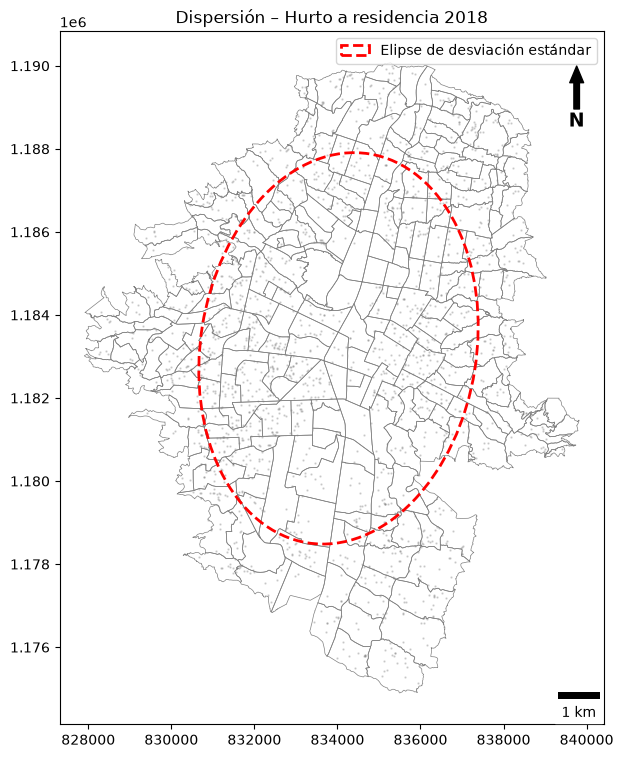

In [132]:
from matplotlib.patches import Ellipse

fig, ax = plt.subplots(figsize=(9, 9))
barrios.plot(ax=ax, facecolor="none", edgecolor="gray", linewidth=0.5)
ax.scatter(coords[:, 0], coords[:, 1], s=0.5, alpha=0.3, color='gray')

ellipse = Ellipse(
    xy=mean_center,
    width=major * 2,
    height=minor * 2,
    angle=np.rad2deg(rotation),
    facecolor='none',
    edgecolor='red',
    linestyle='--',
    linewidth=2,
    label='Elipse de desviación estándar'
)
ax.add_patch(ellipse)
ax.set_aspect('equal')
ax.legend()
ax.set_title('Dispersión – Hurto a residencia 2018')
ax.add_artist(ScaleBar(1, 'm', length_fraction=0.1, location='lower right'))
ax.annotate('N', xy=(0.95, 0.95), xytext=(0.95, 0.87),
            arrowprops=dict(facecolor='black', width=4, headwidth=10),
            ha='center', va='center', fontsize=14, fontweight='bold',
            xycoords='axes fraction')
plt.show()

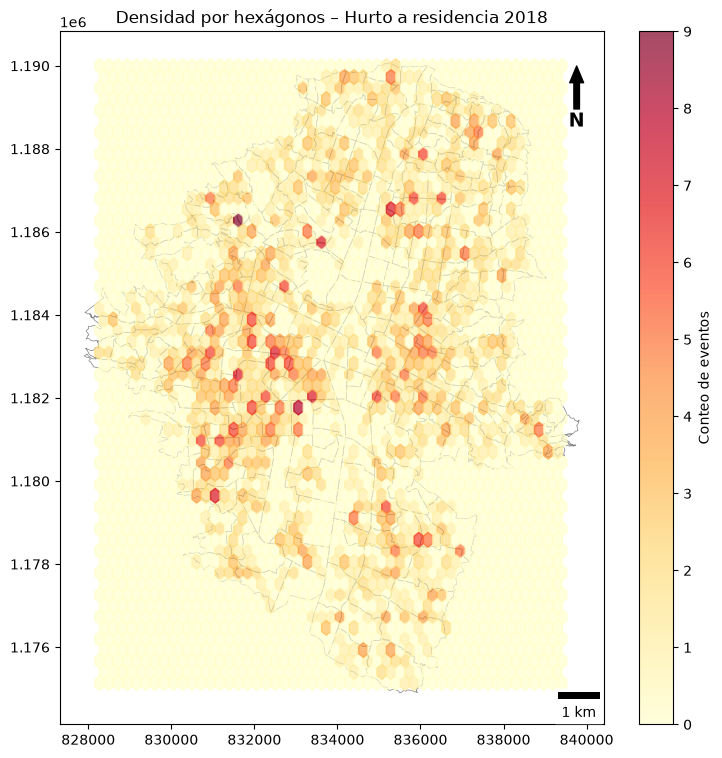

In [133]:
# Ahora pasemos a los métodos de densidad. Primero el hexbin, que cuenta eventos en una malla regular de hexágonos:

fig, ax = plt.subplots(figsize=(9, 9))
barrios.plot(ax=ax, facecolor="none", edgecolor="gray", linewidth=0.5)
hb = ax.hexbin(coords[:, 0], coords[:, 1], gridsize=50, cmap='YlOrRd', alpha=0.7)
ax.set_aspect('equal')
plt.colorbar(hb, ax=ax, label='Conteo de eventos')
ax.set_title('Densidad por hexágonos – Hurto a residencia 2018')
ax.add_artist(ScaleBar(1, 'm', length_fraction=0.1, location='lower right'))
ax.annotate('N', xy=(0.95, 0.95), xytext=(0.95, 0.87),
            arrowprops=dict(facecolor='black', width=4, headwidth=10),
            ha='center', va='center', fontsize=14, fontweight='bold',
            xycoords='axes fraction')
plt.show()

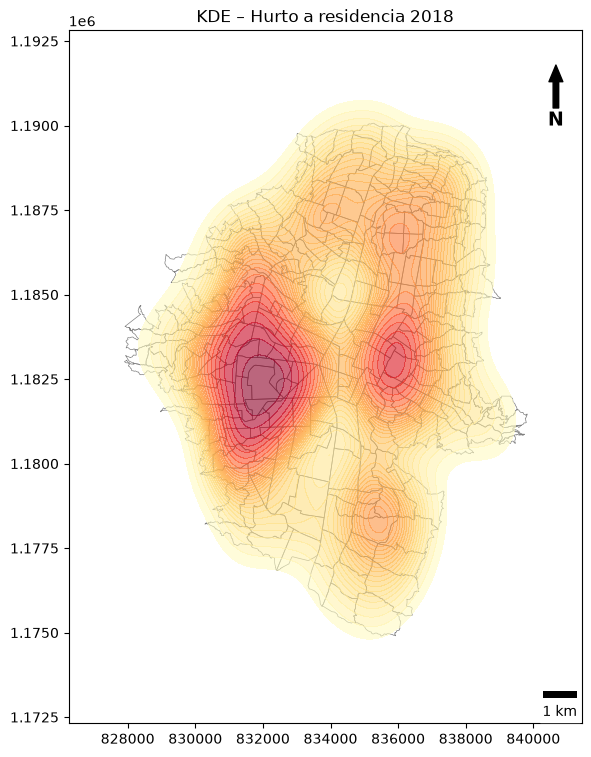

In [134]:
# estimación de densidad por kernel (KDE), que suaviza esa concentración en una superficie continua:

# A diferencia del hexbin, que cuenta eventos en celdas discretas, el KDE estima una función de intensidad continua usando un kernel gaussiano. 
# Cada evento “difunde” su contribución a su alrededor según un ancho de banda (bandwidth) que seaborn calcula automáticamente.

fig, ax = plt.subplots(figsize=(9, 9))
barrios.plot(ax=ax, facecolor="none", edgecolor="gray", linewidth=0.5)
sns.kdeplot(x=coords[:, 0], y=coords[:, 1], levels=30, fill=True, alpha=0.6, cmap='YlOrRd', ax=ax)
ax.set_aspect('equal')
ax.set_title('KDE – Hurto a residencia 2018')
ax.add_artist(ScaleBar(1, 'm', length_fraction=0.1, location='lower right'))
ax.annotate('N', xy=(0.95, 0.95), xytext=(0.95, 0.87),
            arrowprops=dict(facecolor='black', width=4, headwidth=10),
            ha='center', va='center', fontsize=14, fontweight='bold',
            xycoords='axes fraction')
plt.show()

Chi-cuadrado p-valor: 2.095686142865122e-178


<Axes: title={'center': 'Quadrat Count'}>

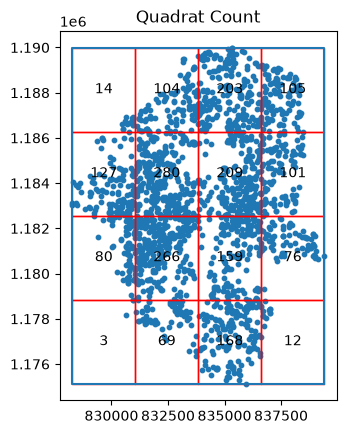

In [94]:
# métodos basados en distancia, que evalúan si el patrón es agrupado, aleatorio o disperso.

# Si el p valor es muy bajo (menor que 0.05), rechazás la hipótesis nula de CSR, lo que indica que los eventos están agrupados. 
# Dado lo que vimos en el KDE, esperarías un p valor muy cercano a cero.

from pointpats import QStatistic

qstat = QStatistic(coords, nx=4, ny=4)
print('Chi-cuadrado p-valor:', qstat.chi2_pvalue)
qstat.plot()

C:\Users\usuario\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


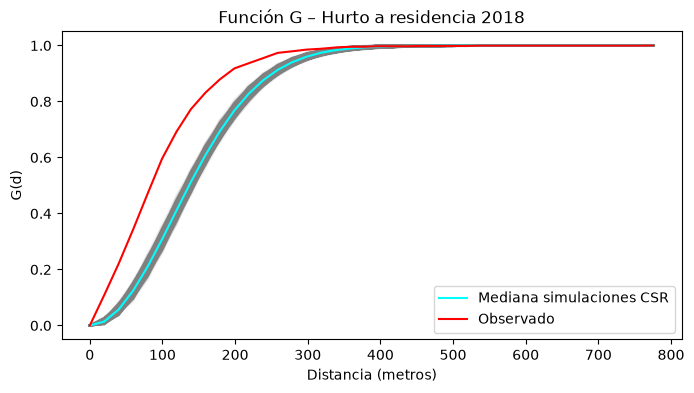

In [95]:
# Ahora vamos con las funciones de Ripley, que son más informativas porque evalúan la agrupación a diferentes escalas de distancia. 
# Empezamos con la función G:

# Las líneas grises son 99 simulaciones bajo CSR (la envolvente). 
# La línea cyan es la mediana de esas simulaciones. La línea roja es tu patrón observado.

# Si la línea roja está por encima de la envolvente, el patrón es agrupado: los eventos tienen vecinos más cercanos de lo esperado 
# bajo aleatoriedad.

from pointpats import distance_statistics

g_test = distance_statistics.g_test(coords, support=40, keep_simulations=True)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(g_test.support, g_test.simulations.T, color='gray', alpha=0.03)
ax.plot(g_test.support, np.median(g_test.simulations, axis=0), color='cyan', label='Mediana simulaciones CSR')
ax.plot(g_test.support, g_test.statistic, color='red', label='Observado')
ax.legend()
ax.set_xlabel('Distancia (metros)')
ax.set_ylabel('G(d)')
ax.set_title('Función G – Hurto a residencia 2018')
plt.show()

C:\Users\usuario\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


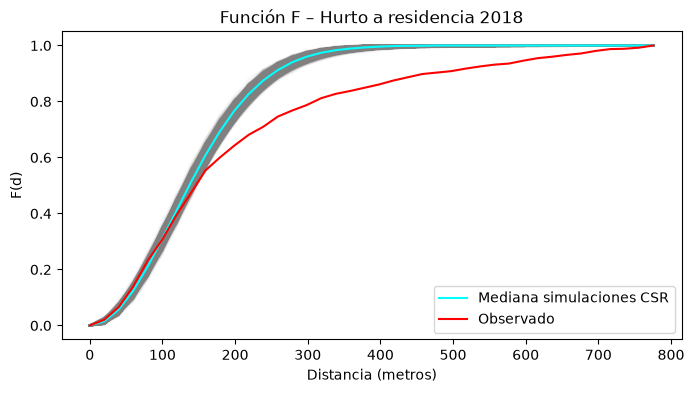

In [96]:
# La función F mide la distancia desde puntos arbitrarios del área de estudio hasta el evento observado más cercano. 
# Es la perspectiva del “espacio vacío”.

f_test = distance_statistics.f_test(coords, support=40, keep_simulations=True)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(f_test.support, f_test.simulations.T, color='gray', alpha=0.03)
ax.plot(f_test.support, np.median(f_test.simulations, axis=0), color='cyan', label='Mediana simulaciones CSR')
ax.plot(f_test.support, f_test.statistic, color='red', label='Observado')
ax.legend()
ax.set_xlabel('Distancia (metros)')
ax.set_ylabel('F(d)')
ax.set_title('Función F – Hurto a residencia 2018')
plt.show()

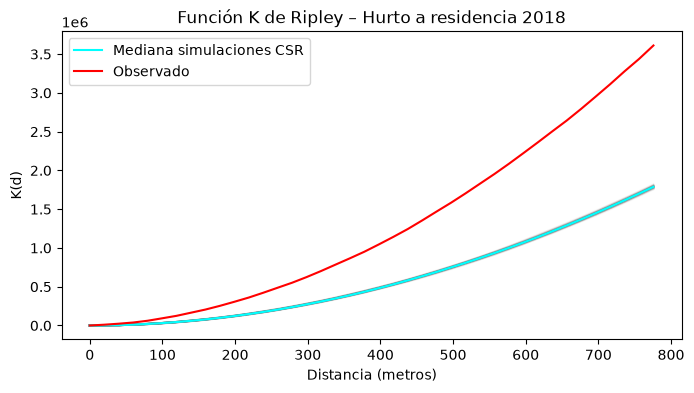

In [136]:
# La función K cuenta el número esperado de eventos dentro de un radio d de cada evento, normalizado por la intensidad global. 
# A diferencia de G y F que solo usan el vecino más cercano, K acumula todos los vecinos dentro del radio, 
# así que captura la estructura a múltiples escalas simultáneamente.

# Si la línea roja está por encima de la envolvente, hay más vecinos de los esperados bajo CSR a esa distancia, es decir, agrupamiento.

k_test = distance_statistics.k_test(coords, support=40, keep_simulations=True, n_simulations=99)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k_test.support, k_test.simulations.T, color='gray', alpha=0.03)
ax.plot(k_test.support, np.median(k_test.simulations, axis=0), color='cyan', label='Mediana simulaciones CSR')
ax.plot(k_test.support, k_test.statistic, color='red', label='Observado')
ax.legend()
ax.set_xlabel('Distancia (metros)')
ax.set_ylabel('K(d)')
ax.set_title('Función K de Ripley – Hurto a residencia 2018')
plt.show()

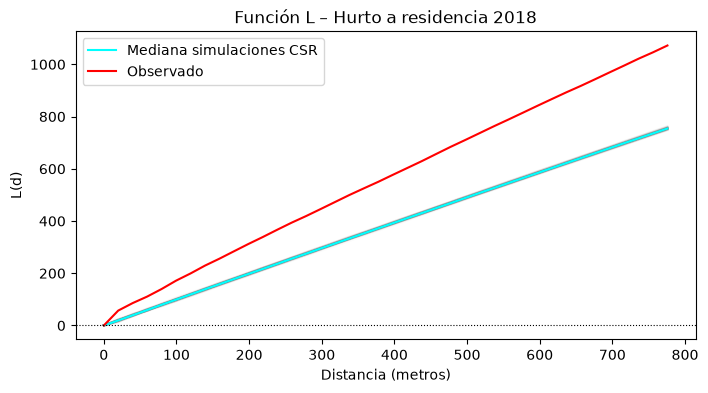

In [137]:
# La función L es una transformación de K que facilita la interpretación. Bajo CSR, L(d) = 0 en todas las distancias (la línea punteada negra). 
# Valores positivos indican agrupamiento a esa distancia, valores negativos indican dispersión. 
# Es más fácil de leer que K porque la referencia es siempre cero.

l_test = distance_statistics.l_test(coords, support=40, keep_simulations=True, n_simulations=99)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(l_test.support, l_test.simulations.T, color='gray', alpha=0.03)
ax.plot(l_test.support, np.median(l_test.simulations, axis=0), color='cyan', label='Mediana simulaciones CSR')
ax.plot(l_test.support, l_test.statistic, color='red', label='Observado')
ax.axhline(y=0, color='black', linestyle=':', linewidth=0.8)
ax.legend()
ax.set_xlabel('Distancia (metros)')
ax.set_ylabel('L(d)')
ax.set_title('Función L – Hurto a residencia 2018')
plt.show()

In [99]:
# DBSCAN agrupa eventos que están cerca entre sí según dos parámetros: eps es la distancia máxima en metros entre dos eventos para considerarlos 
# vecinos (300 metros es un punto de partida razonable para escala de barrio en Medellín), y min_samples es el mínimo de eventos para formar 
# un clúster (50 es conservador para evitar clústeres espurios). 
# Los eventos que no pertenecen a ningún clúster se etiquetan como ruido (label = -1).

from sklearn.cluster import DBSCAN

clusterer = DBSCAN(eps=500, min_samples=30)
labels = clusterer.fit_predict(coords)

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = (labels == -1).sum()
print(f'Clústeres encontrados: {n_clusters}')
print(f'Puntos clasificados como ruido: {n_noise}')

Clústeres encontrados: 3
Puntos clasificados como ruido: 1179


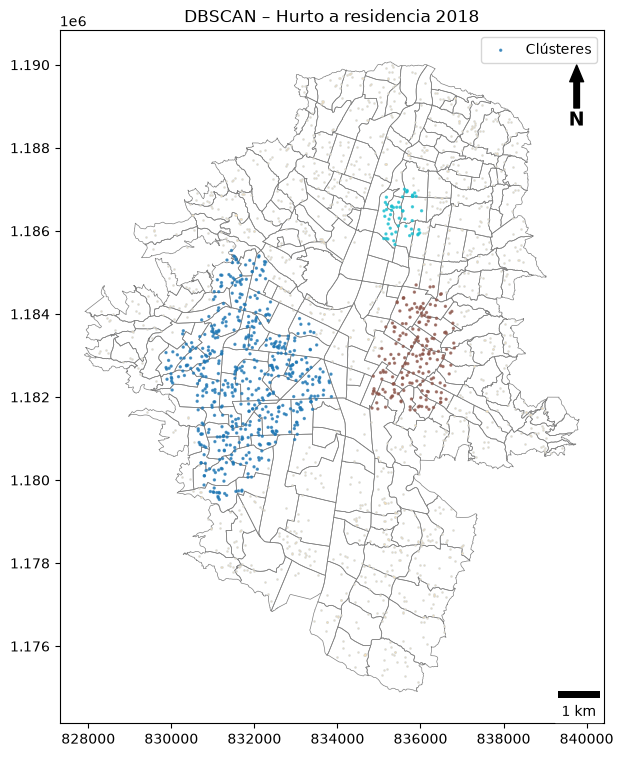

In [128]:
# Los puntos grises son ruido y los colores representan los clústeres identificados. 
# Las zonas con color corresponden a las concentraciones espaciales del delito.

fig, ax = plt.subplots(figsize=(9, 9))

barrios.plot(ax=ax, facecolor="none", edgecolor="gray", linewidth=0.5)

noise = coords[labels == -1]
ax.scatter(noise[:, 0], noise[:, 1], s=0.5, color='lightsteelblue', alpha=0.7)

clustered = coords[labels != -1]
ax.scatter(noise[:, 0], noise[:, 1], s=0.5, color='moccasin', alpha=0.4)
ax.scatter(clustered[:, 0], clustered[:, 1], s=2, c=labels[labels != -1], cmap='tab10', alpha=0.7, label='Clústeres')

ax.set_aspect('equal')
ax.legend()
ax.set_title('DBSCAN – Hurto a residencia 2018')
ax.add_artist(ScaleBar(1, 'm', length_fraction=0.1, location='lower right'))
ax.annotate('N', xy=(0.95, 0.95), xytext=(0.95, 0.87),
            arrowprops=dict(facecolor='black', width=4, headwidth=10),
            ha='center', va='center', fontsize=14, fontweight='bold',
            xycoords='axes fraction')
plt.show()

In [125]:
gdf_2018['cluster'] = labels

In [126]:
# Para cerrar, un conteo de eventos por clúster que te da una tabla de las zonas de concentración:

cluster_summary = gdf_2018[gdf_2018['cluster'] != -1].groupby('cluster').agg(
    n_eventos=('caso', 'count'),
    comunas=('comuna', lambda x: ', '.join(x.unique()))
).sort_values('n_eventos', ascending=False)

print(cluster_summary)

         n_eventos                                            comunas
cluster                                                              
0              553  11 Laureles -  Estadio, 12 La America, 16 Bele...
1              192  10 La Candelaria, 8 Villa Hermosa, 9 Buenos Ai...
2               52                                         4 Aranjuez
